# Classification d'image avec des réseaux pré-entrainés

Pour résoudre un problème de classification d'images sans disposer de millions de données annotées, on utilise souvent des modèles pré-entraînés sur ImageNet (une base de données contenant 1 million d'images et 1000 catégories). Une large gamme de modèles, avec de très bonnes capacités de transfert est disponible.

En classification d'images, on utilise généralement une architecture convolutionnelle ou un Transformer déjà existante et open source.

On supprime le classificateur et éventuellement d'autres couches du modèle, selon la distance entre les types de données.

On ajoute alors un classificateur simple, dédié à la tâche.

Enfin, on peut entraîner le modèle avec les paramètres de base figés ou entrainables.



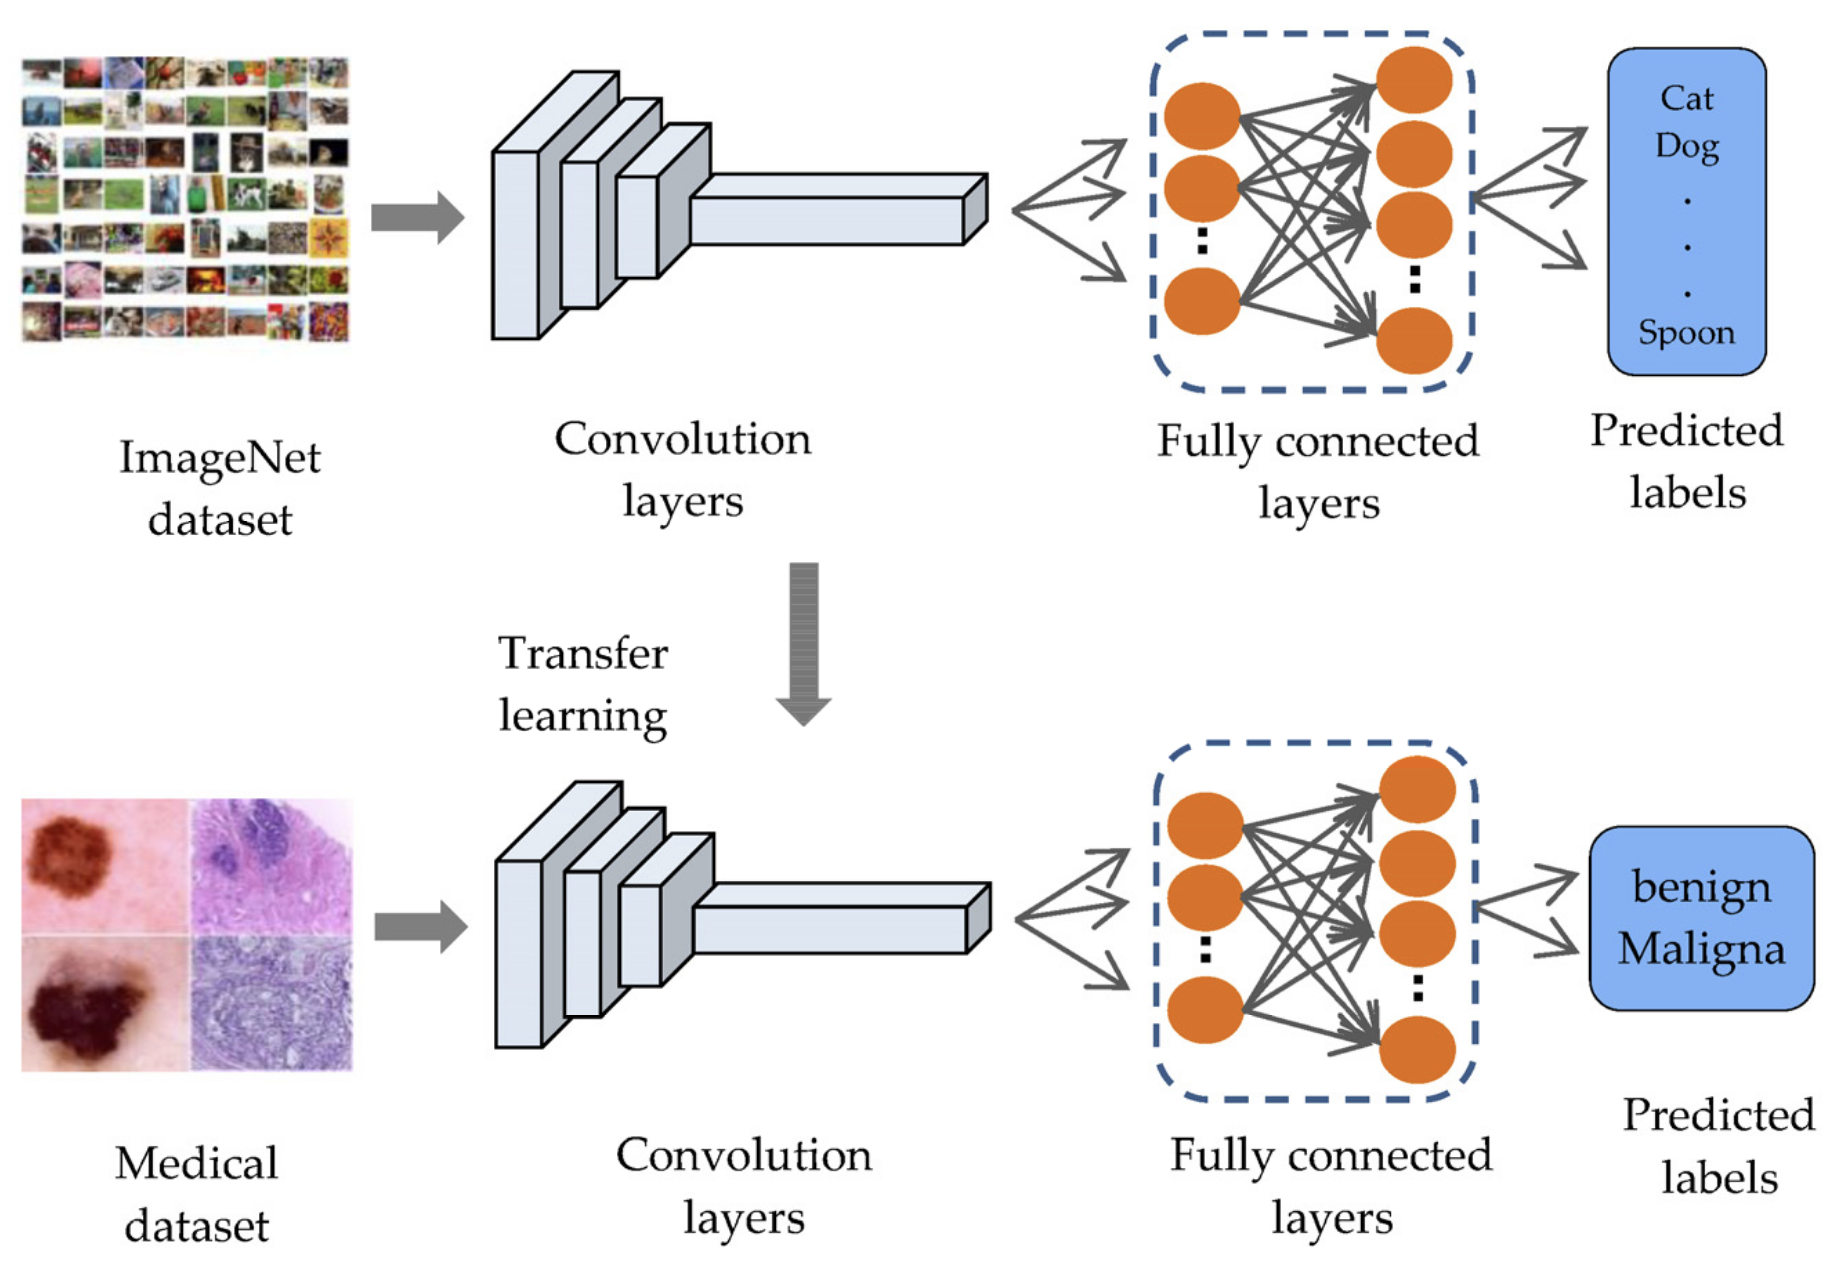


source: "Incorporating a Novel Dual Transfer Learning Approach for
Medical Images"


credits: Ronan Sicre

Dans ce TP, on voit voir les différentes étapes pour entrainer ce genre de modèle sur un dataset d'une centaine d'images.


## 1. Setup

In [ ]:
import numpy as np
import os, torch, torch.nn as nn, torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

### Obtenir le dataset


In [ ]:
!wget --quiet https://pageperso.lis-lab.fr/~ronan.sicre/wordpress/wp-content/uploads/2023/03/miniMIT_Etus.zip
!unzip -qq miniMIT_Etus.zip


### Lister les images

In [ ]:
import os
#import glob

dir_path = 'miniMIT_Etus'
listDir = sorted(os.listdir(dir_path))#glob.glob(dir_path)
print(listDir)

for d in listDir:
  #read subfolder
  listFiles = sorted(os.listdir(dir_path+'/'+d))
  print(listFiles)
  print(len(listFiles))


In [ ]:
num_classes = 3

### Réseaux disponibles

Nous allons utiliser des réseaux disponibles en pytorch et qui sont pré-entrainés sur ImageNet, voir https://docs.pytorch.org/vision/main/models.html

Nous allons d'abord travailler avec un "Efficient Net", puis avec d'autres modèles.

## 2. Dataset & Preprocessing

In [ ]:
data_dir = 'miniMIT_Etus'

train_tf = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train_ds = datasets.ImageFolder(os.path.join(data_dir,'train'), transform=train_tf)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

num_classes = len(train_ds.classes)
print(train_ds.classes)


test_tf = transforms.Compose([
## compléter les transformations pour le jeu de test : les mêmes que pour le jeu de train mais sans les random Flips
  ??
])
test_ds  = datasets.ImageFolder( ?? ) ## à compléter
test_loader  = DataLoader(?? )## à compléter, pas besoin de shuffle pour le jeu de test

## 3. Modèle pré-entrainé (EfficientNet_B0 – Feature Extraction)

In [ ]:
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
for p in model.features.parameters(): p.requires_grad = False

print(model)

model.classifier = nn.Sequential(
    nn.Linear(1280,num_classes)
)

#print(model)

model = model.to(device)



In [ ]:
from torchsummary import summary

summary(model, (3,224,224))


In [ ]:
#print(model.features)
# print(model.avgpool)
# print(model.classifier)

**Question ** : Quels types de couches se trouvent dans features, avgpool et classifier ?

Réponse #TODO

## 4. Training

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.classifier.parameters(), lr=1e-4)

def train_epoch(model, loader):
    model.train(); loss_sum=0; correct=0
    for x,y in loader:
        x,y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out,y)
        loss.backward(); optimizer.step()
        loss_sum += loss.item()*x.size(0)
        correct += (out.argmax(1)==y).sum().item()
    return loss_sum/len(loader.dataset), correct/len(loader.dataset)

for e in range(5):
    l,a = train_epoch(model, train_loader)
    print(f'Epoch {e+1}: loss={l:.4f}, acc={a:.4f}')

## 5. Evaluation

In [ ]:
def evaluate(model, loader):
    model.eval(); correct=0
    with torch.no_grad():
        for x,y in test_loader:
            x,y = x.to(device), y.to(device)
            correct += (model(x).argmax(1)==y).sum().item()
    #print('Test accuracy:', correct/len(test_loader.dataset))
    return (correct/len(test_loader.dataset))


In [ ]:
test_acc = evaluate(model, test_loader)
print('Test accuracy:', test_acc)

## 6. TENSORBOARD

Tensorboard est un outil très pratique pour visualiser les logs de vos experiences.

In [ ]:
%load_ext tensorboard

In [ ]:
from torch.utils.tensorboard import SummaryWriter

# Chaque experience aura son propore repertoire de log
writer = SummaryWriter(log_dir="runs/efficientnet_baseline")

In [ ]:
epochs = 10

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader)
    test_acc = evaluate(model, test_loader)

    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Accuracy/train", train_acc, epoch)
    writer.add_scalar("Accuracy/test", test_acc, epoch)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f}"
    )

writer.close()

In [ ]:
%tensorboard --logdir runs
#Il faudra peut etre le lancer 2 fois pour pouvoir visualiser le tensorboard
#Apres avoir créé un autre run, cliquer sur refresh pour le visualiser.

# Jouer avec le modèle
Créez un tableau de résultats en jouant avec les parametres du modèle :

 - Faites varier les parametres de l'optimiseur puis utilisez ADAM à la place de SGD et trouver un bon learning rate

 - Ajoutez des couches supplémentaires pour le classifieur (par exemple, couche linéaire, RELU, dropout, couche de classification)

Attention: quand vous relancez l'entrainement, le réseau continue avec les parametre précédents, pensez à ré-initialiser votre modèle.

In [ ]:
## TODO

## Comparaison d'architecture

Remplacer l' EfficientNet par un VGG19 et comparer les résultats.


In [ ]:
## TODO

## Rejouez avec l'architecture VGG19

- Testez des variantes pour l'optimiseur
- Utilisez une ou deux couches dense pour la classification
- Ajoutez un global average pooling avant le classifieur


BONUS :
- Ajoutez une normalisation L2 après le global average pooling
- Faites un maxpooling au lieu de l'average pooling.
- Extrayez une couche convolutionelle précédente du réseau (sortie du bloc de convolution précédent)


In [ ]:
## TODO

# Rejouez avec une architecture Transformer

Cette fois-ci, utilisez un Transformer (ViT: Vision Transformer) comme "backbone", à la place d'un CNN.

https://docs.pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html


In [ ]:
## TODO

## Jouez avec de la data Augmentation

Prenez l'un de vos meilleurs modèles et comparez les performances en ajoutant de l'augmentation. Par exemple: `RandomResizedCrop`, `ColorJitter`, etc.

In [ ]:
## TODO

## Jouez avec les Scheduler
Ajoutez un `StepLR` ou `ReduceLROnPlateau` et observez la convergence du modèle

In [ ]:
# TODO

# Le dataset est trop simple...

Utilisez cette version à 5 catégories:
https://pagesperso.irit.fr/~Ronan.Sicre/wp-content/uploads/sites/249/2026/04/miniMIT2.zip
